# 09. Порівняння на official test для w80

**Етап 09 з 13** · NASA C-MAPSS FD001 · RUL prediction

**Мета.** Відтворювано оцінити модель за зафіксованим протоколом і зберегти артефакти для подальшого використання.

**Правило оцінювання.** Official test використовується один раз. Raw і RUL-capped метрики подаються окремо та не змішуються в одному рейтингу.


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [27]:
import os
import random
from pathlib import Path

import copy
import numpy as np
import pandas as pd
import pywt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

# Шлях до даних. На Colab: "/content/drive/MyDrive/predictive_maintenance"
DATA_DIR = Path(os.environ.get("FD001_DIR", "/content/drive/MyDrive/predictive_maintenance"))
OUT_DIR = Path(os.environ.get("FD001_OUT", "outputs"))
OUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
WINDOW_SIZE = 80          # довжина вікна для CNN і LSTM
MAX_EPOCHS = 60
PATIENCE = 10             # скільки епох чекаємо покращення validation MAE
BATCH_SIZE = 64
RUN_DL = True             # False — пропустити CNN/LSTM (швидка перевірка XGBoost)

def set_seed(seed=SEED):
    """Фіксує seed для random, numpy і torch."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


## Дані

In [4]:
COLUMNS = (
    ["unit_id", "cycle", "setting_1", "setting_2", "setting_3"]
    + [f"sensor_{i}" for i in range(1, 22)]
)

def load_fd001(data_dir):
    """Читає train, test і істинний RUL для тестових двигунів."""
    train = pd.read_csv(data_dir / "train_FD001.txt", sep=r"\s+", header=None, names=COLUMNS)
    test = pd.read_csv(data_dir / "test_FD001.txt", sep=r"\s+", header=None, names=COLUMNS)
    rul = pd.read_csv(data_dir / "RUL_FD001.txt", sep=r"\s+", header=None)[0].to_numpy(float)
    # RUL для train: скільки циклів залишилось до останнього циклу двигуна
    train["RUL"] = train.groupby("unit_id")["cycle"].transform("max") - train["cycle"]
    return train, test, rul

train_full, test_full, y_test_true = load_fd001(DATA_DIR)
print("Train:", train_full.shape, "engines:", train_full.unit_id.nunique())
print("Test:", test_full.shape, "engines:", test_full.unit_id.nunique(), "RUL:", y_test_true.shape)

Train: (20631, 27) engines: 100
Test: (13096, 26) engines: 100 RUL: (100,)


## Ознаки

Wavelet: рівень 2, вейвлет `db1` (Haar), вікно 16 циклів. Беремо std детальних коефіцієнтів
другого рівня (`cD2`).

Degradation score: для кожного двигуна базова лінія — медіана перших 20 циклів.
Відхилення сенсорів множимо на очікуваний напрям і відсікаємо від нуля, усереднюємо по сенсорах,
згладжуємо ковзним середнім (вікно 10). Перші 20 циклів мають NaN.

In [5]:
# Налаштування DegradationScore
DETECTOR_DIRECTIONS = {
    "sensor_4": 1,
    "sensor_7": -1,
    "sensor_11": 1,
    "sensor_12": -1,
    "sensor_15": 1,
    "sensor_20": -1,
    "sensor_21": -1
}

BASELINE_CYCLES = 20
DETECTOR_WINDOW = 10

# 25 базових ознак + degradation_score = 26
BASE_FEATURES = (
    ["cycle", "setting_1", "setting_2", "setting_3"]
    + [f"sensor_{i}" for i in range(1, 22)]
)

FEATURES = BASE_FEATURES + [
    "degradation_score",
    "degradation_warmup"
]

class DegradationScore:
    """Directional sensor-deviation score, масштаби оцінюються тільки на train."""

    def __init__(self, baseline_cycles=BASELINE_CYCLES, window=DETECTOR_WINDOW):
        self.baseline_cycles = baseline_cycles
        self.window = window
        self.sensors = list(DETECTOR_DIRECTIONS)
        self.direction = pd.Series(DETECTOR_DIRECTIONS)
        self.scale_ = None

    def _engine_score(self, engine):
        values = engine[self.sensors]
        baseline = values.iloc[:self.baseline_cycles].median()
        deviation = values.sub(baseline).div(self.scale_)
        directional = deviation.mul(self.direction).clip(lower=0)
        raw = directional.mean(axis=1)
        return raw.rolling(self.window, min_periods=1).mean()

    def fit(self, train_df):
        residuals = []

        for _, eng in train_df.sort_values("cycle").groupby("unit_id", sort=False):
            calib = eng[self.sensors].iloc[:self.baseline_cycles]
            residuals.append(calib.sub(calib.median()))

        resid = pd.concat(residuals, ignore_index=True)

        self.scale_ = (
            resid.abs().median() * 1.4826
        ).clip(lower=1e-6)

        return self

    def transform(self, df):
        result = pd.Series(
            np.nan,
            index=df.index,
            name="degradation_score"
        )

        for _, eng in df.sort_values("cycle").groupby("unit_id", sort=False):
            score = self._engine_score(eng).to_numpy(copy=True)
            score[:self.baseline_cycles] = np.nan
            result.loc[eng.index] = score

        return result


def build_features(df, detector):
    """Повертає DataFrame з 27 ознаками без Wavelet."""

    out = df.copy()

    out["degradation_score"] = detector.transform(out)

    out["degradation_warmup"] = (
        out["degradation_score"].notna().astype(np.float32)
    )
    return out

In [6]:
print("FEATURES:", len(FEATURES))
print(FEATURES)

assert len(FEATURES) == 27

FEATURES: 27
['cycle', 'setting_1', 'setting_2', 'setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21', 'degradation_score', 'degradation_warmup']


## Спліт train / validation

Спліт такий самий, як у дослідженнях (`GroupShuffleSplit`, 20% двигунів).
Детектор фітиться тільки на train-частині.

In [7]:

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, va_idx = next(splitter.split(train_full, groups=train_full["unit_id"]))
train_raw = train_full.iloc[tr_idx].copy()
val_raw = train_full.iloc[va_idx].copy()
print("Train engines:", train_raw.unit_id.nunique(), "rows:", len(train_raw))
print("Validation engines:", val_raw.unit_id.nunique(), "rows:", len(val_raw))

detector = DegradationScore().fit(train_raw)
train_df = build_features(train_raw, detector)
val_df = build_features(val_raw, detector)

# Для тесту фічі рахуємо по всій історії кожного двигуна,
# а потім беремо останній цикл (саме його оцінює official test).
test_df = build_features(test_full, detector)
test_last = test_df.sort_values("cycle").groupby("unit_id").tail(1).sort_values("unit_id")

print("Feature count:", len(FEATURES))
print("NaN у train (очікувано — перші 20 циклів через degradation_score):",
      int(train_df[FEATURES].isna().sum().sum()))
assert len(test_last) == len(y_test_true) == 100

Train engines: 80 rows: 16561
Validation engines: 20 rows: 4070
Feature count: 27
NaN у train (очікувано — перші 20 циклів через degradation_score): 1600


## XGBoost

Параметри — з найкращого Optuna-пошуку (`xgb_baseline`). NaN XGBoost обробляє сам.

In [8]:
XGB_PARAMS = {
    "n_estimators": 300,
    "learning_rate": 0.012074507989018332,
    "max_depth": 4,
    "min_child_weight": 3.2298041995296414,
    "subsample": 0.7900204897773602,
    "colsample_bytree": 0.9223090698240903,
    "reg_alpha": 0.7459635164536705,
    "reg_lambda": 4.416722489003329,
    "gamma": 0.2695542352154229,
    "objective": "reg:squarederror",
    "random_state": SEED,
    "n_jobs": -1,
    "tree_method": "hist",
}

xgb_model = XGBRegressor(**XGB_PARAMS)
xgb_model.fit(train_df[FEATURES], train_df["RUL"])

xgb_val_pred = np.clip(xgb_model.predict(val_df[FEATURES]), 0, None)
print("XGBoost validation MAE:", round(mean_absolute_error(val_df["RUL"], xgb_val_pred), 3))

XGBoost validation MAE: 18.979


## Нейромережі: нормалізація і вікна

Скейлер фітиться тільки на train. NaN після нормалізації замінюємо нулем
(0 — це середнє після стандартизації) і додаємо окремий індикатор
`degradation_available`, щоб мережа бачила, де score ще не обчислений.

In [9]:

def prepare_nn_frame(df, feature_cols=FEATURES, scaler=None):
    """
    Проста масштабація ознак для нейромережі.
    Якщо scaler не передано, він навчається на наданому df (train).
    """
    out = df.copy()
    cols = list(feature_cols)

    # Якщо scaler ще немає, навчаємо його
    if scaler is None:
        scaler = StandardScaler()
        scaler.fit(out[cols].fillna(0).to_numpy(dtype=np.float64))

    # Трансформуємо колонки
    out[cols] = scaler.transform(
        out[cols].fillna(0).to_numpy(dtype=np.float64)
    )

    return out, cols, scaler

train_nn, NN_COLS, scaler = prepare_nn_frame(train_df)
val_nn, _, _ = prepare_nn_frame(val_df, scaler=scaler)
test_nn, _, _ = prepare_nn_frame(test_df, scaler=scaler)

def make_train_windows(df, cols, window):
    """Вікна (window, n_features) з кожного двигуна; ціль — RUL в останньому циклі вікна."""
    X, y = [], []
    for _, eng in df.sort_values("cycle").groupby("unit_id", sort=False):
        feats = eng[cols].to_numpy(np.float32)
        rul = eng["RUL"].to_numpy(np.float32)
        for end in range(window, len(eng) + 1):
            X.append(feats[end - window:end])
            y.append(rul[end - 1])
    return np.asarray(X, np.float32), np.asarray(y, np.float32)

def make_last_windows(df, cols, window):
    """Останнє вікно кожного двигуна (для official test). Короткі історії паддяться зліва."""
    X = []
    for _, eng in df.sort_values("cycle").groupby("unit_id", sort=True):
        feats = eng[cols].to_numpy(np.float32)
        if len(feats) < window:
            # історія коротша за вікно: доповнюємо зліва першим рядком (edge padding)
            pad = np.repeat(feats[:1], window - len(feats), axis=0)
            feats = np.vstack([pad, feats])
        X.append(feats[-window:])
    return np.asarray(X, np.float32)

X_train, y_train = make_train_windows(train_nn, NN_COLS, WINDOW_SIZE)
X_val, y_val = make_train_windows(val_nn, NN_COLS, WINDOW_SIZE)
X_test = make_last_windows(test_nn, NN_COLS, WINDOW_SIZE)
print("Windows train/val/test:", X_train.shape, X_val.shape, X_test.shape)

# Діагностика: скільки двигунів не мають повного вікна
for name, d in [("train", train_nn), ("val", val_nn), ("test", test_nn)]:
    lens = d.groupby("unit_id").size()
    print(f"{name}: двигунів коротших за WINDOW_SIZE={WINDOW_SIZE}: {(lens < WINDOW_SIZE).sum()} з {len(lens)} (мін. довжина {lens.min()})")
assert len(X_val) > 0 and X_test.shape == (100, WINDOW_SIZE, len(NN_COLS))

Windows train/val/test: (10241, 80, 27) (2490, 80, 27) (100, 80, 27)
train: двигунів коротших за WINDOW_SIZE=80: 0 з 80 (мін. довжина 128)
val: двигунів коротших за WINDOW_SIZE=80: 0 з 20 (мін. довжина 135)
test: двигунів коротших за WINDOW_SIZE=80: 23 з 100 (мін. довжина 31)


## Моделі

In [10]:
class RULCNN(nn.Module):
    """1D-CNN без пулінгу: два Conv1d, потім повнозв'язний шар."""

    def __init__(self, in_features, window, dropout_p=0.3):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(in_features, 32, kernel_size=3), nn.ReLU(),
            nn.Conv1d(32, 64, kernel_size=3), nn.ReLU(),
        )
        flat = 64 * (window - 4)  # кожен conv з k=3 вкорочує послідовність на 2
        self.head = nn.Sequential(
            nn.Flatten(), nn.Linear(flat, 64), nn.ReLU(),
            nn.Dropout(dropout_p), nn.Linear(64, 1),
        )

    def forward(self, x):
        # x: (batch, window, features) -> Conv1d очікує (batch, features, window)
        x = self.conv(x.transpose(1, 2))
        return self.head(x).squeeze(-1)

class RULLSTM(nn.Module):
    """Один LSTM-шар; прогноз з останнього прихованого стану."""

    def __init__(self, in_features, hidden_size=64):
        super().__init__()
        self.lstm = nn.LSTM(in_features, hidden_size, num_layers=1, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        _, (h_n, _) = self.lstm(x)
        return self.fc(h_n[-1]).squeeze(-1)

def train_nn_model(model, X_tr, y_tr, X_va, y_va, lr=1e-3):
    """Навчає з MSE, зберігає ваги найкращої епохи за validation MAE.

    Повертає (model з найкращими вагами, history).
    """
    loader = DataLoader(TensorDataset(torch.from_numpy(X_tr), torch.from_numpy(y_tr)),
                        batch_size=BATCH_SIZE, shuffle=True)
    X_va_t = torch.from_numpy(X_va).to(DEVICE)
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    best_mae, best_state, best_epoch, bad = float("inf"), None, 0, 0
    history = {"train_mse": [], "val_mae": []}
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        running = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            running += loss.item() * len(xb)
        history["train_mse"].append(running / len(X_tr))

        model.eval()
        with torch.no_grad():
            pred = model(X_va_t).cpu().numpy()
        val_mae = mean_absolute_error(y_va, pred)
        history["val_mae"].append(val_mae)

        if val_mae < best_mae:
            best_mae, best_epoch, bad = val_mae, epoch, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                break

    model.load_state_dict(best_state)
    print(f"{type(model).__name__}: best epoch {best_epoch}, validation MAE {best_mae:.3f}")
    return model, {"best_epoch": best_epoch, "best_val_mae": best_mae, **history}

## Тренування CNN і LSTM

In [11]:
cnn_model, cnn_hist = None, None
lstm_model, lstm_hist = None, None

if RUN_DL:
    set_seed()
    cnn_model, cnn_hist = train_nn_model(
        RULCNN(len(NN_COLS), WINDOW_SIZE), X_train, y_train, X_val, y_val)

    set_seed()
    lstm_model, lstm_hist = train_nn_model(
        RULLSTM(len(NN_COLS)), X_train, y_train, X_val, y_val)
else:
    print("RUN_DL=False: CNN і LSTM пропущено")

RULCNN: best epoch 19, validation MAE 9.069
RULLSTM: best epoch 31, validation MAE 8.120


## Оцінка на офіційному тесті

Для XGBoost беремо ознаки останнього циклу кожного двигуна,
для CNN і LSTM — останнє вікно з 80 циклів (`WINDOW_SIZE`; якщо історія коротша — паддинг першим рядком). Прогноз обрізаємо знизу нулем.

In [12]:
def metrics(y_true, y_pred, name):
    """MAE, RMSE і R2 для одного набору прогнозів."""
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

# official test: порядок рядків test_last відповідає unit_id 1..100 і RUL_FD001
test_xgb_X = test_last[FEATURES]
xgb_test_pred = np.clip(xgb_model.predict(test_xgb_X), 0, None)

rows = [metrics(y_test_true, xgb_test_pred, "XGBoost")]
predictions = pd.DataFrame({"unit_id": test_last["unit_id"].to_numpy(),
                            "RUL_true": y_test_true,
                            "XGBoost": xgb_test_pred})

if RUN_DL:
    for name, model in [("CNN", cnn_model), ("LSTM", lstm_model)]:
        model.eval()
        with torch.no_grad():
            pred = np.clip(model(torch.from_numpy(X_test).to(DEVICE)).cpu().numpy(), 0, None)
        rows.append(metrics(y_test_true, pred, name))
        predictions[name] = pred

results = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
display(results.round(3))
results.round(4).to_csv(OUT_DIR / "final_test_metrics.csv", index=False)
predictions.to_csv(OUT_DIR / "final_test_predictions.csv", index=False)
print("Saved:", OUT_DIR / "final_test_metrics.csv", OUT_DIR / "final_test_predictions.csv")

,Model,MAE,RMSE,R2
0,LSTM,10.430,16.288,0.846
1,XGBoost,15.571,22.180,0.715
2,CNN,15.884,28.043,0.545


Saved: outputs/final_test_metrics.csv outputs/final_test_predictions.csv


# Покращуємо LSTM + ansambell

In [13]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

WINDOW_SIZE = 80
HIDDEN_SIZE = 64
DROPOUT = 0.3
BATCH_SIZE = 64
EPOCHS = 100
LEARNING_RATE = 1e-3
PATIENCE = 12

ASYMMETRY_WEIGHTS = [1.25, 1.5, 2.0]

print("Device:", DEVICE)
print("Asymmetry weights:", ASYMMETRY_WEIGHTS)

Device: cuda
Asymmetry weights: [1.25, 1.5, 2.0]


In [14]:
# CELL 2 — Перевірка даних без повторної обробки

X_train_np = np.asarray(X_train, dtype=np.float32)
X_val_np = np.asarray(X_val, dtype=np.float32)

y_train_np = np.asarray(y_train, dtype=np.float32).reshape(-1)
y_val_np = np.asarray(y_val, dtype=np.float32).reshape(-1)

assert X_train_np.ndim == 3
assert X_val_np.ndim == 3

assert X_train_np.shape[1] == WINDOW_SIZE
assert X_val_np.shape[1] == WINDOW_SIZE

assert X_train_np.shape[2] == X_val_np.shape[2]
assert len(X_train_np) == len(y_train_np)
assert len(X_val_np) == len(y_val_np)

print("Train:", X_train_np.shape, y_train_np.shape)
print("Validation:", X_val_np.shape, y_val_np.shape)
print("Features:", X_train_np.shape[2])
print("RUL train range:", y_train_np.min(), y_train_np.max())
print("RUL val range:", y_val_np.min(), y_val_np.max())

Train: (10241, 80, 27) (10241,)
Validation: (2490, 80, 27) (2490,)
Features: 27
RUL train range: 0.0 282.0
RUL val range: 0.0 189.0


In [34]:
# CELL 3 — NASA Score

def nasa_score(y_true, y_pred) -> float:
    """Асиметричний штраф C-MAPSS: запізнілий прогноз (error>0) карається сильніше."""
    err = np.asarray(y_pred, dtype=np.float64) - np.asarray(y_true, dtype=np.float64)
    return float(np.sum(np.where(err < 0, np.exp(-err / 13) - 1, np.exp(err / 10) - 1)))


def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)

    error = y_pred - y_true

    return {
        "MAE": float(np.mean(np.abs(error))),
        "RMSE": float(np.sqrt(np.mean(error ** 2))),
        "NASA Score": nasa_score(y_true, y_pred),
        "Overprediction %": float(np.mean(error > 0) * 100),
        "Underprediction %": float(np.mean(error < 0) * 100),
        "Mean error": float(np.mean(error))
    }

In [17]:
class AsymmetricHuberLoss(nn.Module):
    def __init__(self, over_weight=1.5, under_weight=1.0, delta=10.0):
        super().__init__()

        self.over_weight = over_weight
        self.under_weight = under_weight
        self.delta = delta

    def forward(self, pred, target):
        error = pred - target
        abs_error = torch.abs(error)

        huber = torch.where(
            abs_error <= self.delta,
            0.5 * error ** 2,
            self.delta * (abs_error - 0.5 * self.delta)
        )

        weights = torch.where(
            error > 0,
            self.over_weight,
            self.under_weight
        )

        return (weights * huber).mean()

In [18]:
# CELL 5 — LSTM з асиметричним Loss

class RULLSTMAsymmetric(nn.Module):
    """Один LSTM-шар; прогноз з останнього прихованого стану."""

    def __init__(self, in_features, hidden_size=64):
        super().__init__()

        self.lstm = nn.LSTM(
            in_features,
            hidden_size,
            num_layers=1,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        _, (h_n, _) = self.lstm(x)
        return self.fc(h_n[-1]).squeeze(-1)

In [19]:
X_train_tensor = torch.tensor(X_train_np, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_np, dtype=torch.float32)

X_val_tensor = torch.tensor(X_val_np, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_np, dtype=torch.float32)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [36]:
# CELL 7 — Навчання NASA-aware LSTM

def train_asymmetric_lstm(over_weight, experiment_name):
    # Однаковий seed для відтворюваності
    torch.manual_seed(SEED)
    np.random.seed(SEED)

    model = RULLSTMAsymmetric(
        in_features=X_train_np.shape[2],
        hidden_size=HIDDEN_SIZE
    ).to(DEVICE)

    criterion = AsymmetricHuberLoss(
        over_weight=over_weight,
        under_weight=1.0,
        delta=10.0
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    best_score = float("inf")
    best_epoch = 0
    best_state = None
    patience_counter = 0

    history = []

    for epoch in range(1, EPOCHS + 1):

        # ---------- TRAIN ----------
        model.train()
        train_losses = []

        for xb, yb in train_loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad()

            predictions = model(xb)
            loss = criterion(predictions, yb)

            loss.backward()
            optimizer.step()

            train_losses.append(loss.item())

        # ---------- VALIDATION ----------
        model.eval()

        val_predictions = []
        val_targets = []

        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(DEVICE)

                predictions = model(xb)

                val_predictions.extend(
                    predictions.cpu().numpy()
                )
                val_targets.extend(yb.numpy())

        metrics = regression_metrics(
            val_targets,
            val_predictions
        )

        history.append({
            "epoch": epoch,
            "train_loss": np.mean(train_losses),
            **metrics
        })

        current_score = metrics["NASA Score"]

        if current_score < best_score:
            best_score = current_score
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            patience_counter = 0

        else:
            patience_counter += 1

        if epoch == 1 or epoch % 5 == 0:
            print(
                f"Epoch {epoch:03d} | "
                f"Loss: {np.mean(train_losses):.4f} | "
                f"Val MAE: {metrics['MAE']:.4f} | "
                f"Val NASA: {current_score:.2f}"
            )

        if patience_counter >= PATIENCE:
            print(f"Early stopping at epoch {epoch}")
            break

    model.load_state_dict(best_state)

    save_path = f"{experiment_name}.pt"

    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "input_size": X_train_np.shape[2],
            "hidden_size": HIDDEN_SIZE,
            "dropout": DROPOUT,
            "over_weight": over_weight,
            "best_epoch": best_epoch,
            "best_val_nasa": best_score
        },
        save_path
    )

    print(
        f"\nBest epoch: {best_epoch} | "
        f"Best validation NASA Score: {best_score:.2f}"
    )

    return model, pd.DataFrame(history)

In [37]:
asymmetric_models = {}
asymmetric_histories = {}

for weight in ASYMMETRY_WEIGHTS:
    name = f"lstm_nasa_over_{str(weight).replace('.', '_')}"

    print(f"\n{'=' * 60}")
    print(f"Training: {name}")
    print(f"{'=' * 60}")

    model, history = train_asymmetric_lstm(
        over_weight=weight,
        experiment_name=name
    )

    asymmetric_models[weight] = model
    asymmetric_histories[weight] = history


Training: lstm_nasa_over_1_25
Epoch 001 | Loss: 602.1915 | Val MAE: 54.9625 | Val NASA: 25273523.86
Epoch 005 | Loss: 303.2432 | Val MAE: 28.4062 | Val NASA: 1334979.10
Epoch 010 | Loss: 154.0631 | Val MAE: 15.4571 | Val NASA: 106366.23
Epoch 015 | Loss: 104.7979 | Val MAE: 11.1555 | Val NASA: 25376.88
Epoch 020 | Loss: 77.8680 | Val MAE: 9.4968 | Val NASA: 13246.99
Epoch 025 | Loss: 57.4295 | Val MAE: 9.0985 | Val NASA: 8986.65
Epoch 030 | Loss: 57.4498 | Val MAE: 8.6359 | Val NASA: 8010.48
Epoch 035 | Loss: 31.2599 | Val MAE: 8.4420 | Val NASA: 7797.68
Epoch 040 | Loss: 22.9267 | Val MAE: 8.5233 | Val NASA: 11117.35
Early stopping at epoch 41

Best epoch: 31 | Best validation NASA Score: 7572.40

Training: lstm_nasa_over_1_5
Epoch 001 | Loss: 602.4581 | Val MAE: 54.9633 | Val NASA: 25308163.74
Epoch 005 | Loss: 303.0882 | Val MAE: 28.4025 | Val NASA: 1327796.70
Epoch 010 | Loss: 156.4588 | Val MAE: 15.7744 | Val NASA: 110941.73
Epoch 015 | Loss: 107.2662 | Val MAE: 11.2332 | Val NAS

In [38]:
results = []

for weight, model in asymmetric_models.items():
    model.eval()

    with torch.no_grad():
        predictions = model(
            X_val_tensor.to(DEVICE)
        ).cpu().numpy()

    metrics = regression_metrics(y_val_np, predictions)

    results.append({
        "Model": f"LSTM α={weight}",
        **metrics
    })

results_df = pd.DataFrame(results).set_index("Model")

display(
    results_df.sort_values("NASA Score")
)

,MAE,RMSE,NASA Score,Overprediction %,Underprediction %,Mean error
Model,,,,,,
LSTM α=2.0,7.970369,12.619268,6596.616665,45.823293,54.176707,-1.357303
LSTM α=1.25,8.550570,13.412930,7572.403643,32.449799,67.550201,-4.178802
LSTM α=1.5,8.202358,13.239679,7689.415894,55.903614,44.096386,-0.666228


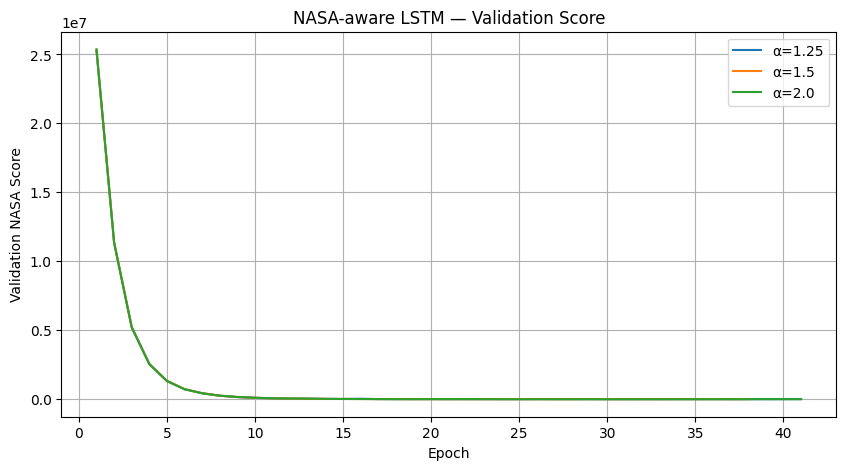

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

for weight, history in asymmetric_histories.items():
    plt.plot(
        history["epoch"],
        history["NASA Score"],
        label=f"α={weight}"
    )

plt.xlabel("Epoch")
plt.ylabel("Validation NASA Score")
plt.title("NASA-aware LSTM — Validation Score")
plt.legend()
plt.grid()
plt.show()

In [40]:
# CELL — Аналіз найбільших помилок LSTM α=2.0

best_model = asymmetric_models[2.0]
best_model.eval()

with torch.no_grad():
    val_pred = best_model(
        X_val_tensor.to(DEVICE)
    ).cpu().numpy()

errors = val_pred - y_val_np

error_analysis = pd.DataFrame({
    "y_true": y_val_np,
    "y_pred": val_pred,
    "error": errors,
    "abs_error": np.abs(errors),
    "NASA_penalty": np.where(
        errors < 0,
        np.exp(-errors / 13) - 1,
        np.exp(errors / 10) - 1
    )
})

display(
    error_analysis.sort_values(
        "NASA_penalty",
        ascending=False
    ).head(15)
)

print("Total NASA Score:", error_analysis["NASA_penalty"].sum())
print("Max penalty:", error_analysis["NASA_penalty"].max())

,y_true,y_pred,error,abs_error,NASA_penalty
1860,98.0,144.030838,46.030838,46.030838,98.791565
2241,169.0,109.178947,-59.821053,59.821053,98.645538
1987,58.0,103.140915,45.140915,45.140915,90.294579
1859,99.0,144.136307,45.136307,45.136307,90.252541
1983,62.0,105.701645,43.701645,43.701645,78.056625
2242,168.0,111.338615,-56.661385,56.661385,77.145164
2240,170.0,113.851166,-56.148834,56.148834,74.124062
1986,59.0,102.009888,43.009888,43.009888,72.772697
2239,171.0,115.378319,-55.621681,55.621681,71.138702
1985,60.0,102.768021,42.768021,42.768021,71.009789


Total NASA Score: 6596.6167
Max penalty: 98.79156494140625


In [41]:
# CELL — Аналіз помилок за діапазонами RUL

error_analysis["rul_group"] = pd.cut(
    error_analysis["y_true"],
    bins=[-1, 30, 60, 90, 125, 200, 500],
    labels=[
        "0-30",
        "31-60",
        "61-90",
        "91-125",
        "126-200",
        "200+"
    ]
)

group_analysis = error_analysis.groupby(
    "rul_group",
    observed=True
).agg(
    samples=("error", "count"),
    MAE=("abs_error", "mean"),
    Mean_Error=("error", "mean"),
    NASA_Score=("NASA_penalty", "sum"),
    Overprediction=("error", lambda x: (x > 0).mean() * 100)
)

display(group_analysis)

,samples,MAE,Mean_Error,NASA_Score,Overprediction
rul_group,,,,,
0-30,620,2.135280,0.631680,147.843597,53.064516
31-60,595,4.525283,1.223189,691.192444,50.756303
61-90,517,8.173635,3.071197,1448.335571,47.195358
91-125,401,11.041465,-2.500888,1399.720825,39.650873
126-200,357,20.101974,-14.241108,2909.523926,29.971989


In [43]:
print("=== NORMAL DATA ===")

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)

print("y_train range:", y_train.min(), y_train.max())
print("y_val range:", y_val.min(), y_val.max())

print("Validation above 125:", np.sum(np.asarray(y_val) > 125))

=== NORMAL DATA ===
X_train: (10241, 80, 27)
X_val: (2490, 80, 27)
y_train range: 0.0 282.0
y_val range: 0.0 189.0
Validation above 125: 357
